<a href="https://colab.research.google.com/github/costpetrides/Data_Analysis_Atmosphere/blob/main/Autocorrelation/Autocorrelation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt




$$
r_k =
\frac{
\sum_{i=1}^{n-k}
(x_i-\bar{x}_{-})(x_{i+k}-\bar{x}_{+})
}{
\sqrt{
\left[\sum_{i=1}^{n-k}(x_i-\bar{x}_{-})^2\right]
\left[\sum_{i=k+1}^{n}(x_i-\bar{x}_{+})^2\right]
}
}
$$




# METHOD 1: EXPLICIT VECTORISED INDEXING

Lag     Autocorrelation
1       0.52
2       0.27
3       0.2
4       0.23
5       0.08


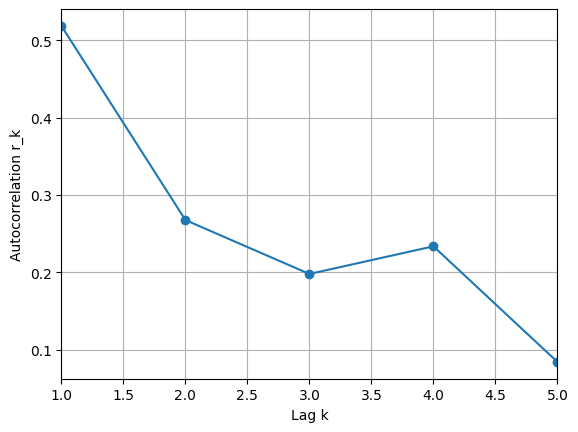

In [39]:
x = np.array([33,32,30,29,25,30,37,37,29,30,36,32,33,34,53,45,
              25,28,32,27,26,28,24,26,9,22,17,26,27,30,34])

n = len(x)
maxLag = 5
r1 = np.zeros(maxLag)

for k in range(1, maxLag+1):

    L = 0
    R = k
    i = np.arange(L, n-R)

    x1 = x[i]
    x2 = x[i+k]

    m1 = np.mean(x1)
    m2 = np.mean(x2)

    numerator = np.sum((x1-m1)*(x2-m2))
    denominator = np.sqrt(np.sum((x1-m1)**2) *
                          np.sum((x2-m2)**2))

    r1[k-1] = numerator / denominator

print("Lag     Autocorrelation")
for k in range(1, maxLag+1):
    print(k, "     ", round(r1[k-1], 2))

plt.plot(range(1, maxLag + 1), r1, 'o-', linewidth=1.5)
plt.xlabel('Lag k')
plt.ylabel('Autocorrelation r_k')
plt.xlim(1,5)
plt.grid(True)
plt.show()

# Method 2 - Slicing

Lag     Autocorrelation
1       0.5188116649081126
2       0.26767515634908967
3       0.19794507112598922
4       0.23371916280078633
5       0.08415845740146032




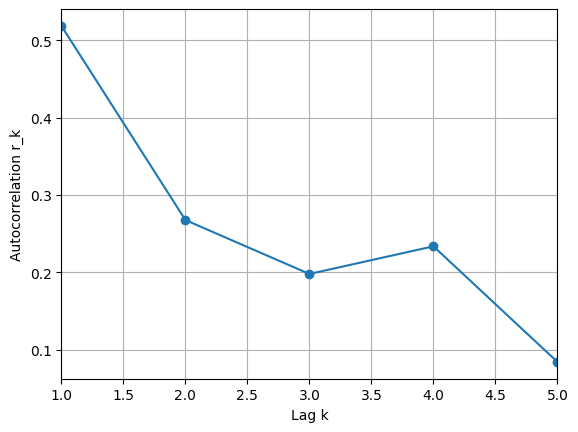

In [36]:
# Data
x = np.array([33,32,30,29,25,30,37,37,29,30,36,32,33,34,53,45,
              25,28,32,27,26,28,24,26,9,22,17,26,27,30,34])

n = len(x)

# Maximum lag
maxLag = 5
r = np.zeros(maxLag)

for k in range(1, maxLag + 1):

    x1 = x[0:n-k]
    x2 = x[k:n]

    m1 = np.mean(x1)
    m2 = np.mean(x2)

    numerator = np.sum((x1-m1) * (x2-m2))

    denominator = np.sqrt(
        np.sum((x1-m1)**2) *
        np.sum((x2-m2)**2)
    )

    r[k-1] = numerator / denominator

# Results
print("Lag     Autocorrelation")

for k in range(1, maxLag + 1):
    print(k, "     ", r[k-1])

# Plot
print("\n")
plt.plot(range(1, maxLag + 1), r, 'o-', linewidth=1.5)
plt.xlabel('Lag k')
plt.ylabel('Autocorrelation r_k')
plt.xlim(1,5)
plt.grid(True)
plt.show()